In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
from io import StringIO

# Most recent backtest log
log_file = sorted(glob.glob('backtests/*.log'))[-1]
print('Using:', log_file)

with open(log_file) as f:
    content = f.read()

act_idx = content.find('Activities log:\n')
act_data = content[act_idx + len('Activities log:\n'):]
end_idx = act_data.find('\n\n')
if end_idx > 0:
    act_data = act_data[:end_idx]

df = pd.read_csv(StringIO(act_data), sep=';')

OPTIONS = [p for p in sorted(df['product'].unique()) if p.startswith('VEV_')]
DAYS = sorted(df['day'].unique())
print('Options:', OPTIONS)
print('Days:', DAYS)

Using: backtests/2026-04-27_11-40-41.log
Options: ['VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Days: [3]


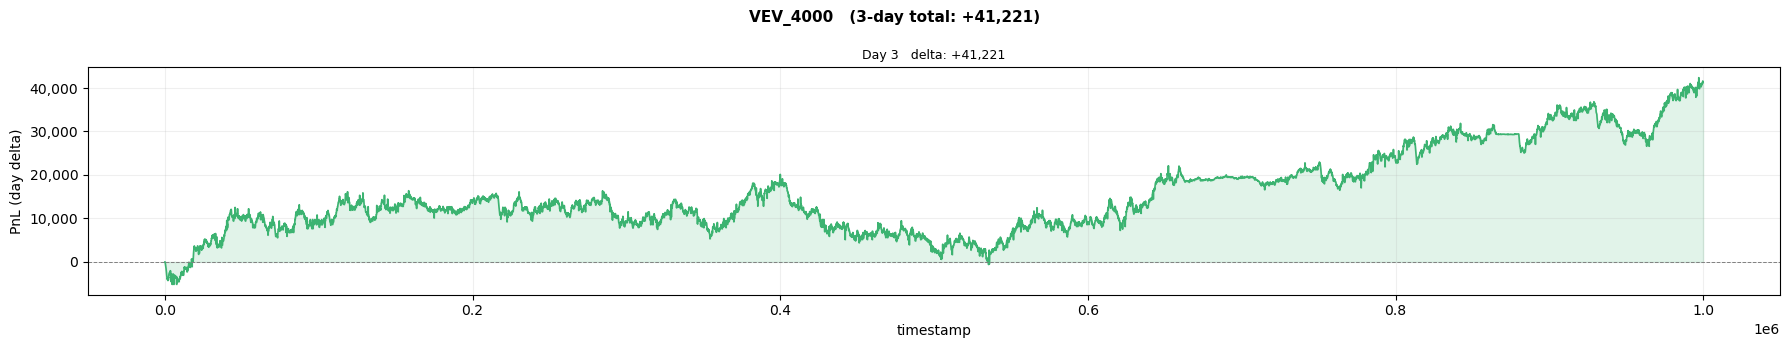

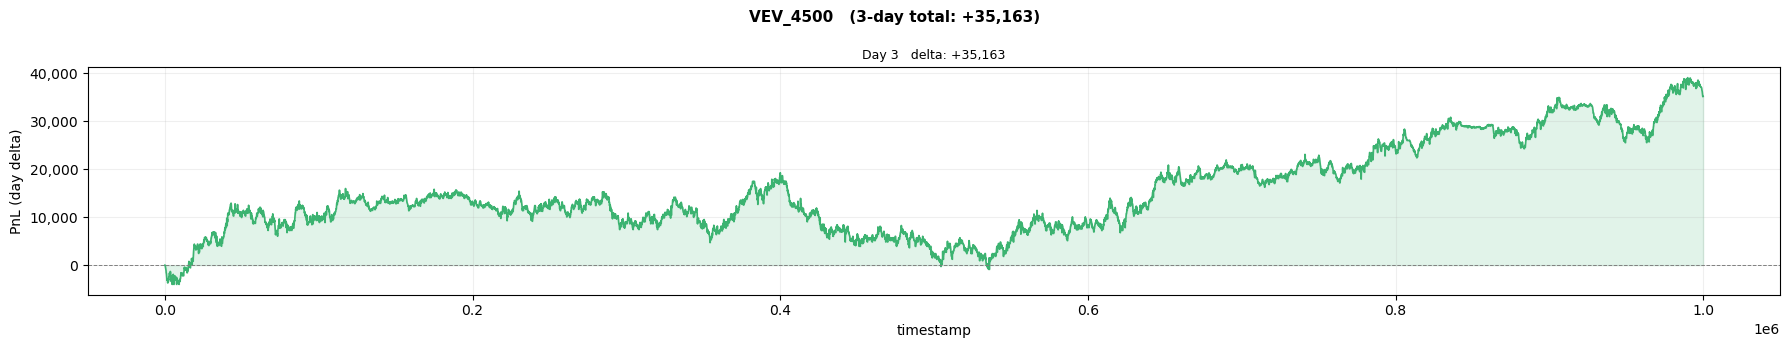

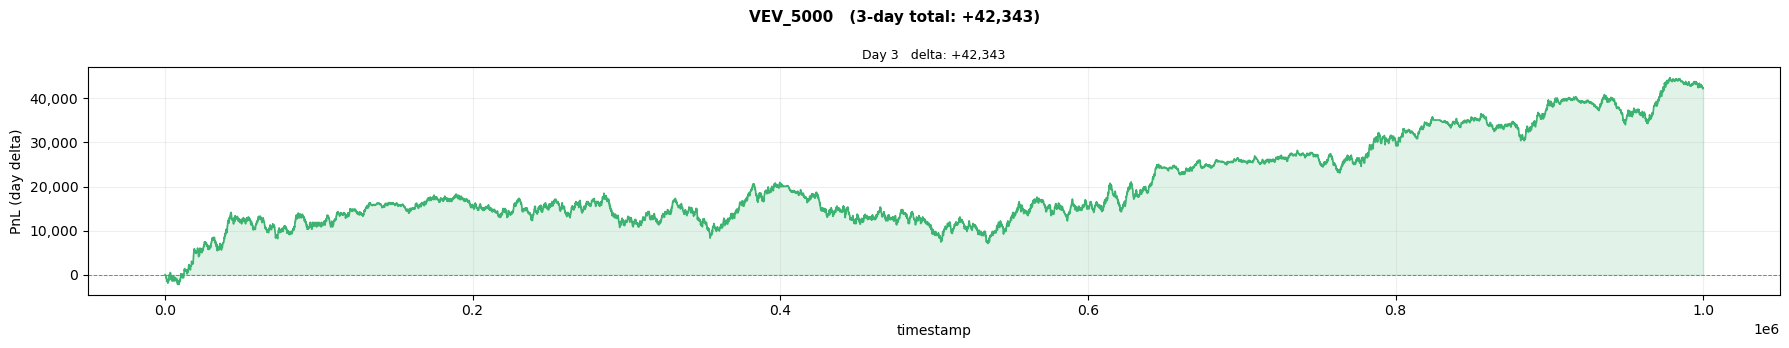

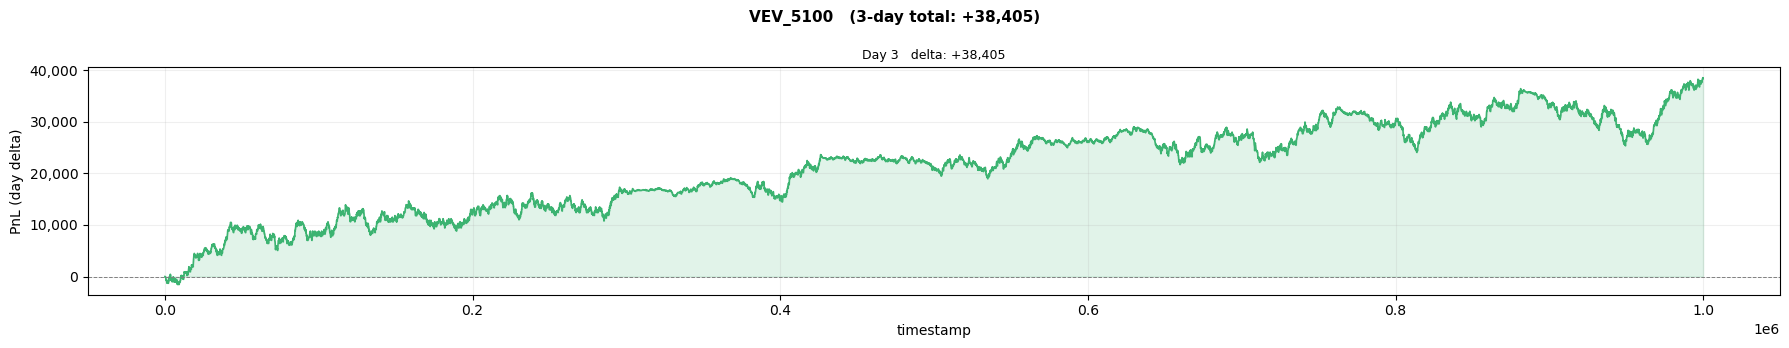

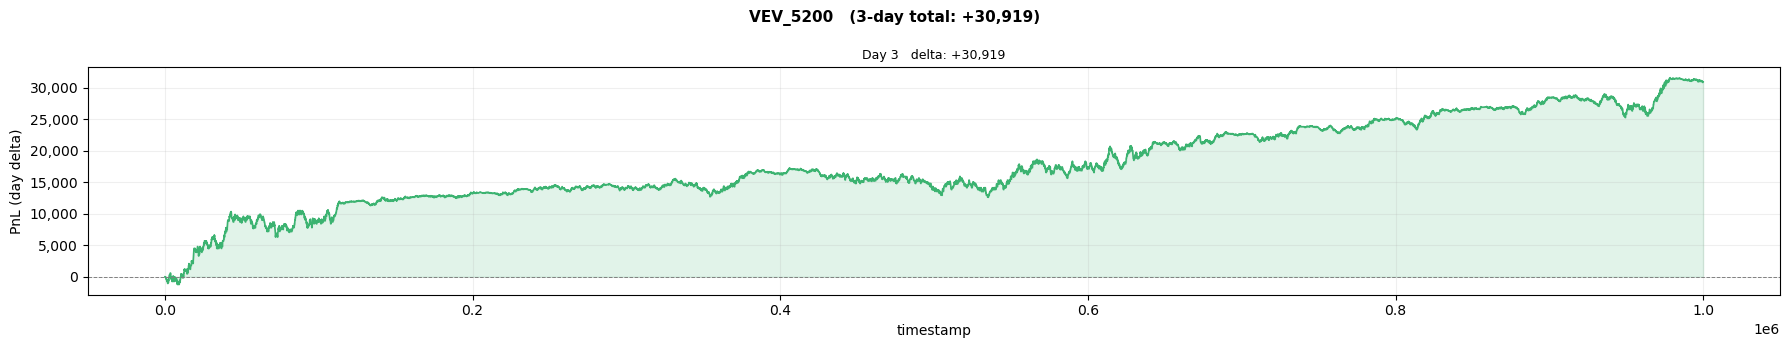

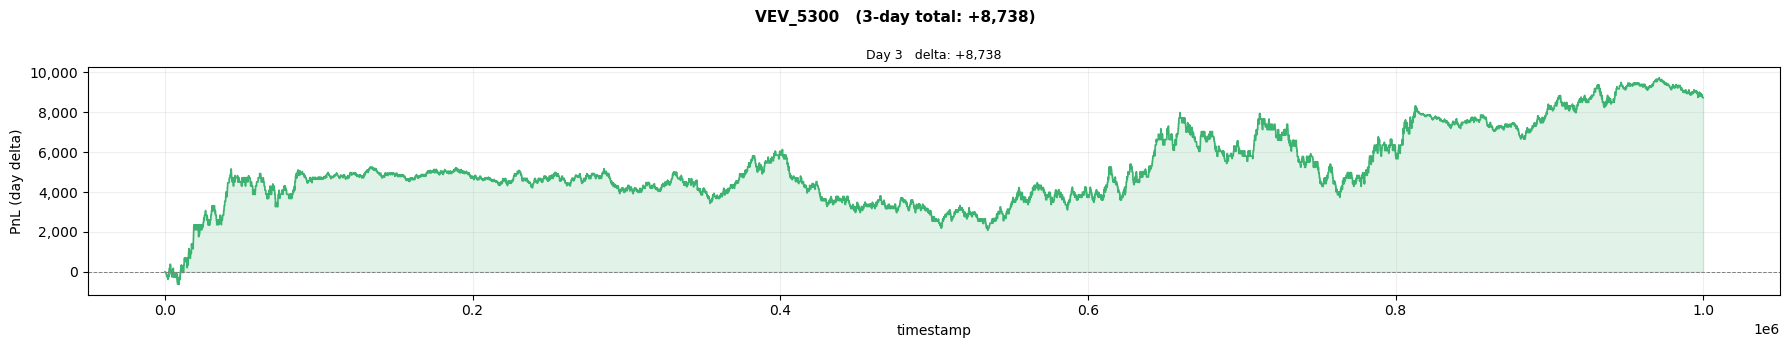

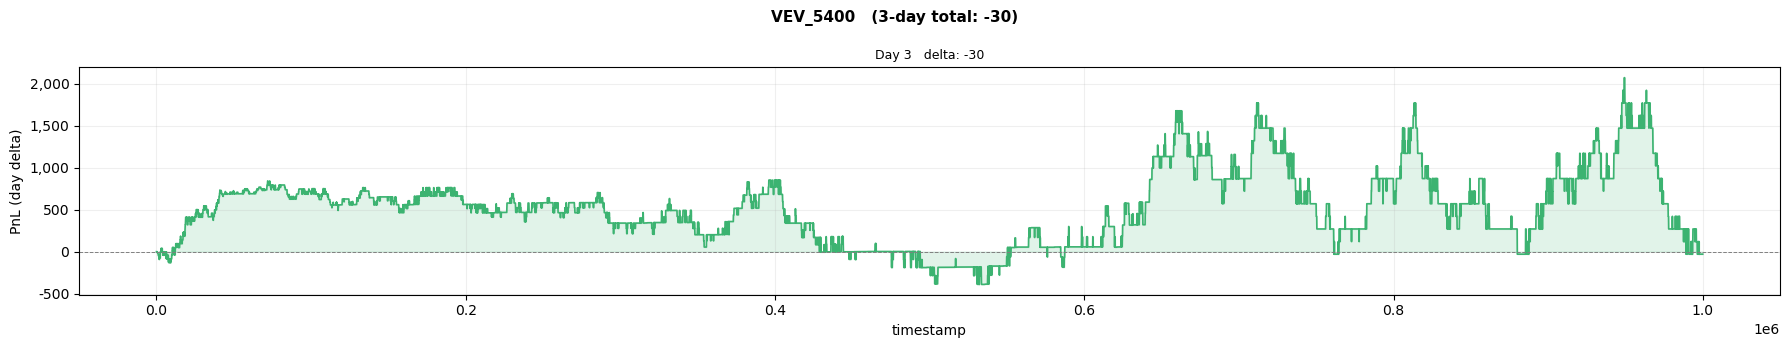

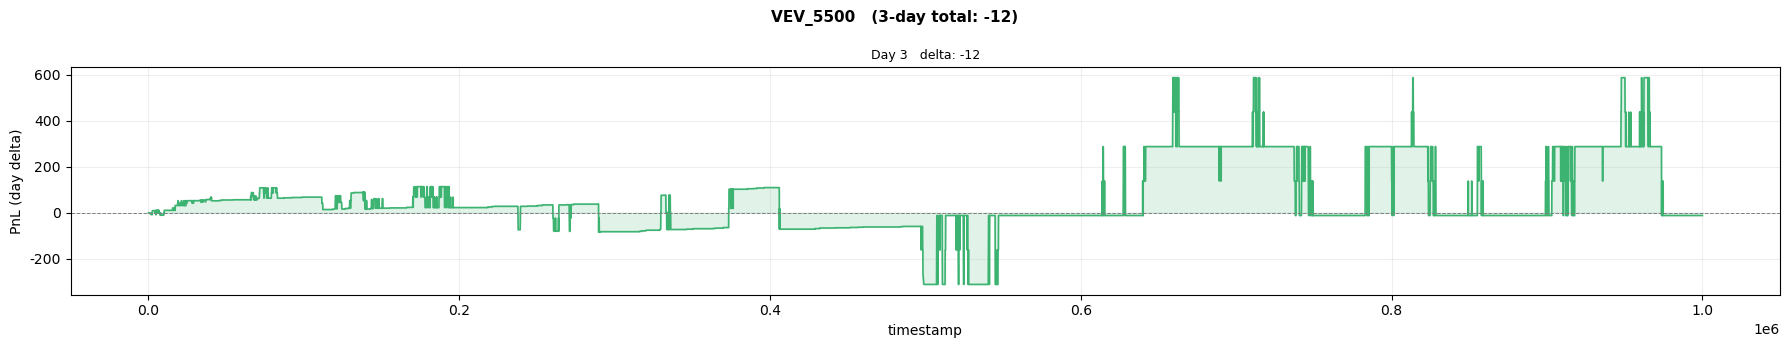

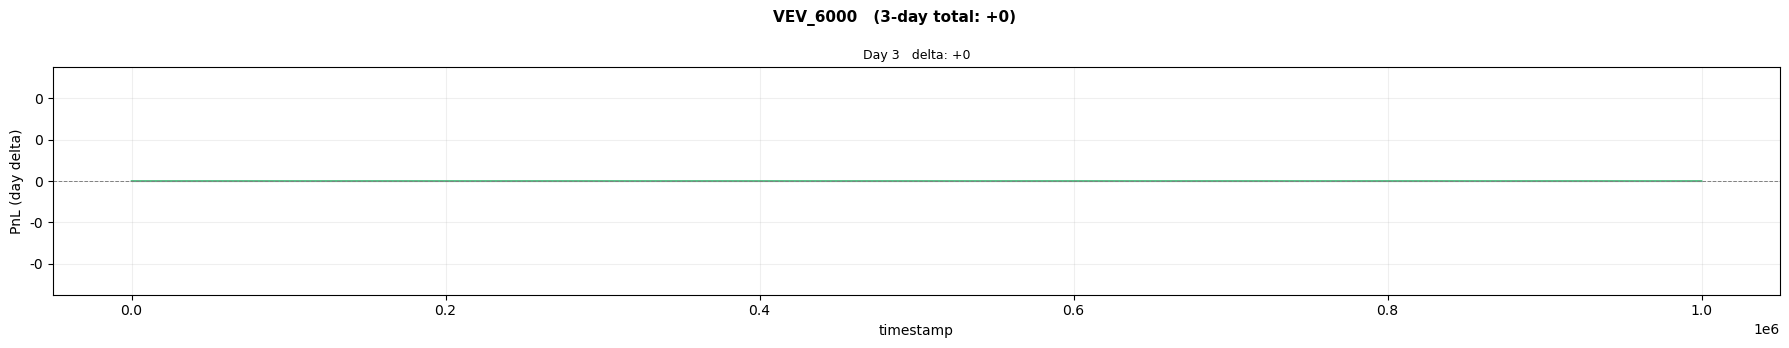

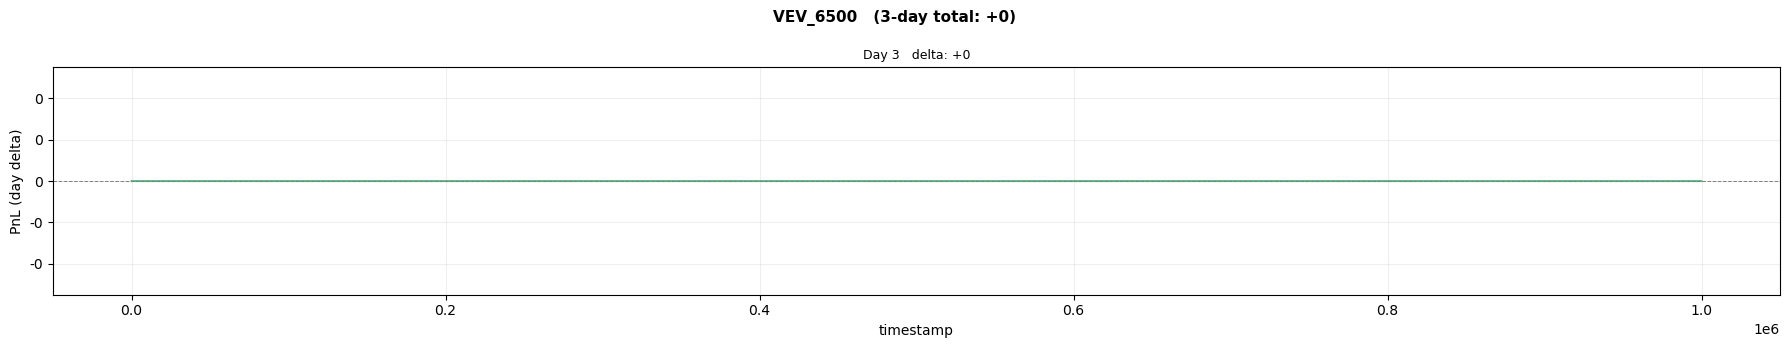

In [15]:
# PnL over time — one figure per option, 3 subplots (one per day)
DAY_COLORS = {1: 'steelblue', 2: 'darkorange', 3: 'mediumseagreen'}

for opt in OPTIONS:
    sub = df[df['product'] == opt]
    fig, axes = plt.subplots(1, len(DAYS), figsize=(18, 3.5), sharey=False)
    if len(DAYS) == 1:
        axes = [axes]

    for ax, day in zip(axes, DAYS):
        d = sub[sub['day'] == day].copy()
        if d.empty:
            ax.set_visible(False)
            continue

        # PnL relative to start of this day
        pnl_start = d['profit_and_loss'].iloc[0]
        daily_pnl = d['profit_and_loss'] - pnl_start

        c = DAY_COLORS[day]
        ax.plot(d['timestamp'], daily_pnl, color=c, lw=1.2)
        ax.fill_between(d['timestamp'], daily_pnl, alpha=0.15, color=c)
        ax.axhline(0, color='grey', lw=0.7, ls='--')

        eod = daily_pnl.iloc[-1]
        ax.set_title(f'Day {day}   delta: {eod:+,.0f}', fontsize=9)
        ax.set_xlabel('timestamp')
        ax.set_ylabel('PnL (day delta)' if day == DAYS[0] else '')
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
        ax.grid(True, alpha=0.2)

    cumulative_total = sub.groupby('day')['profit_and_loss'].last().diff().fillna(
        sub.groupby('day')['profit_and_loss'].last()
    ).sum()
    fig.suptitle(f'{opt}   (3-day total: {cumulative_total:+,.0f})', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

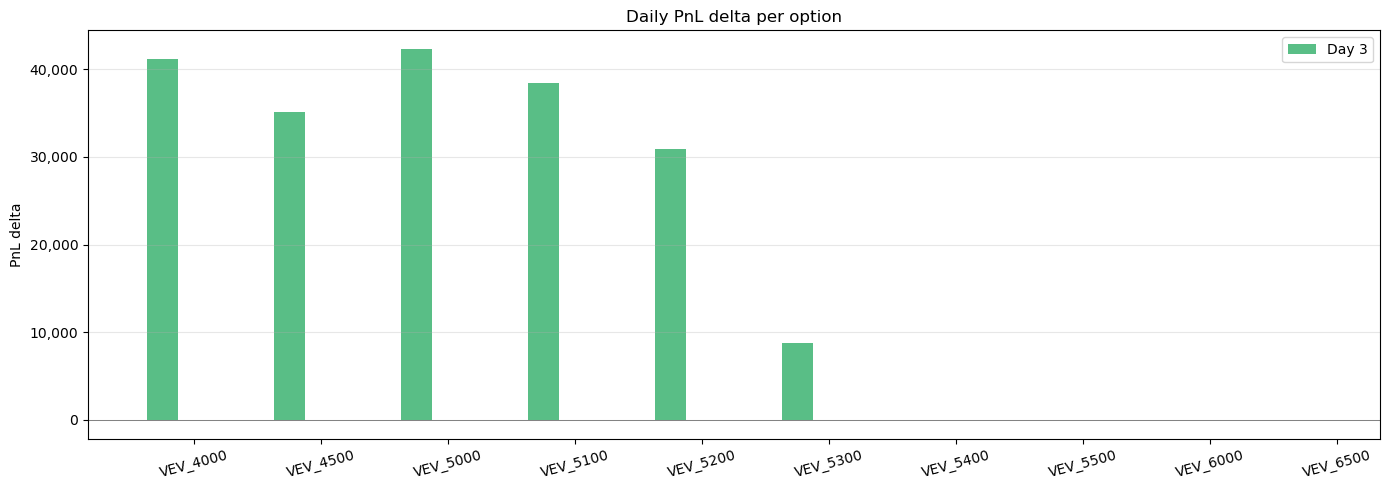

In [16]:
# Summary bar chart — daily PnL delta per option
DAY_COLORS = {1: 'steelblue', 2: 'darkorange', 3: 'mediumseagreen'}

summary = {}
for opt in OPTIONS:
    sub = df[df['product'] == opt]
    deltas = []
    prev = 0
    for day in DAYS:
        d = sub[sub['day'] == day]['profit_and_loss']
        eod = d.iloc[-1] if not d.empty else prev
        deltas.append(eod - prev)
        prev = eod
    summary[opt] = deltas

import numpy as np
x = np.arange(len(OPTIONS))
w = 0.25
fig, ax = plt.subplots(figsize=(14, 5))
for i, day in enumerate(DAYS):
    vals = [summary[o][i] for o in OPTIONS]
    ax.bar(x + i * w, vals, width=w, label=f'Day {day}',
           color=DAY_COLORS[day], alpha=0.85)

ax.set_xticks(x + w)
ax.set_xticklabels(OPTIONS, rotation=15)
ax.set_ylabel('PnL delta')
ax.set_title('Daily PnL delta per option')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.axhline(0, color='grey', lw=0.7)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


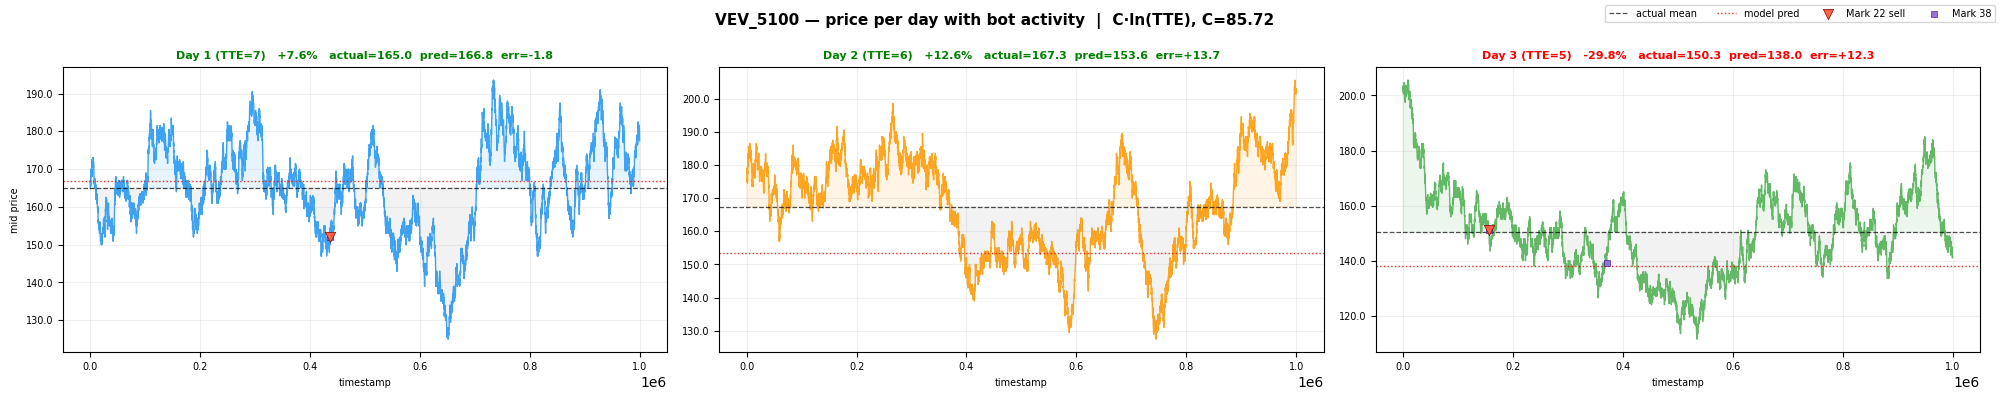

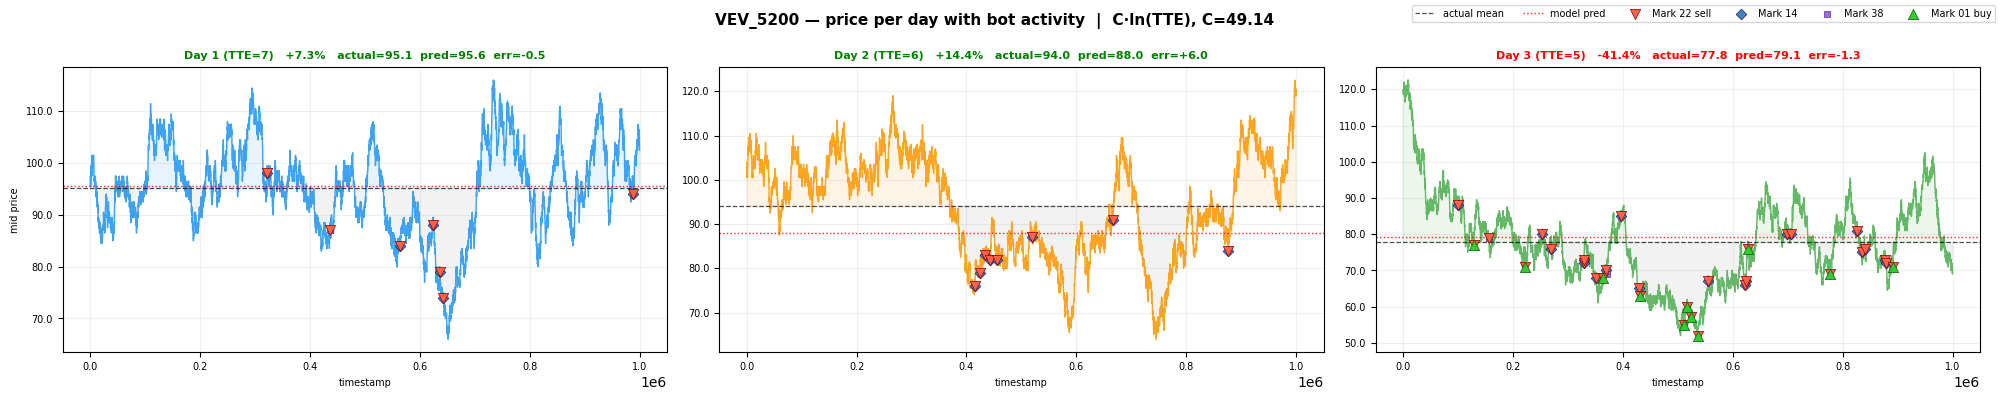

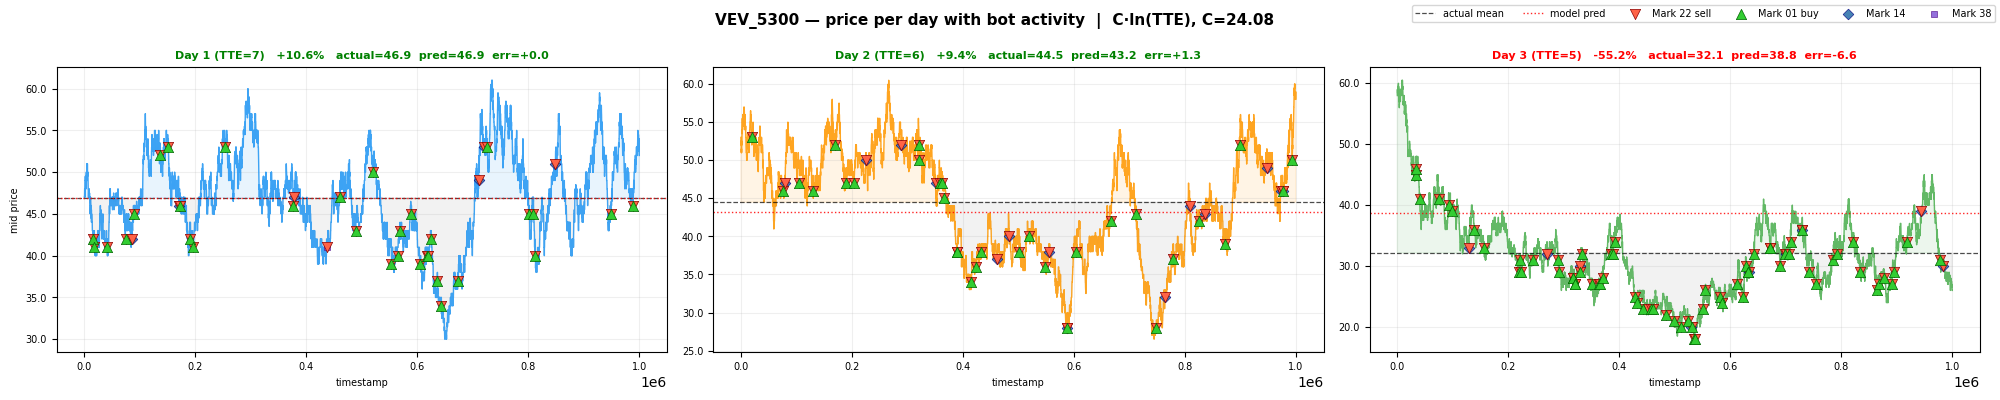

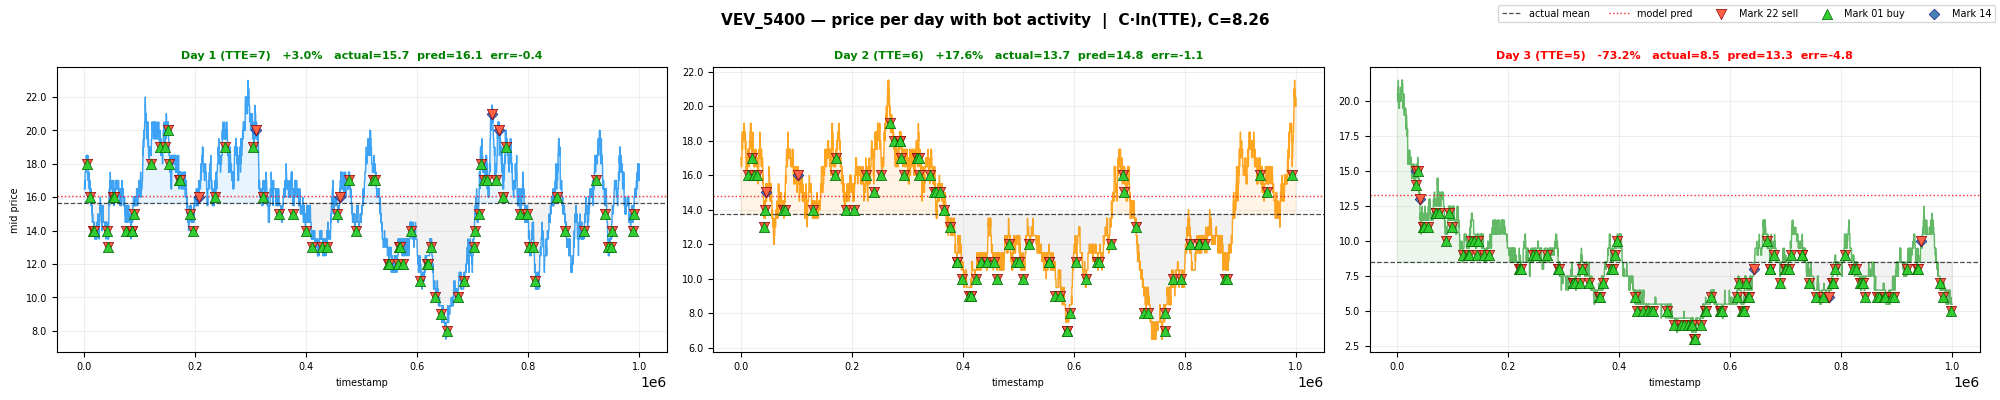

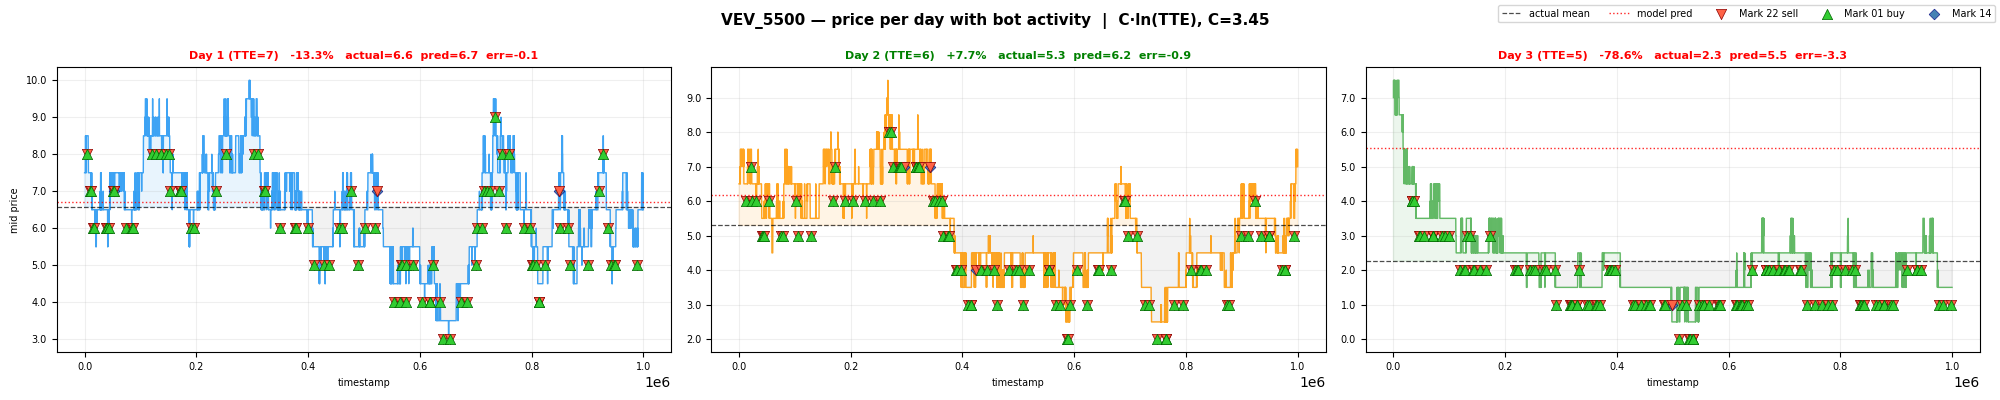

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

DATA = Path('ROUND_4')
DAYS = [1, 2, 3]

prices_frames, trades_frames = [], []
for d in DAYS:
    p = pd.read_csv(DATA / f'prices_round_4_day_{d}.csv', sep=';')
    p['day'] = d
    prices_frames.append(p)
    t = pd.read_csv(DATA / f'trades_round_4_day_{d}.csv', sep=';')
    t['day'] = d
    trades_frames.append(t)

prices = pd.concat(prices_frames, ignore_index=True)
trades = pd.concat(trades_frames, ignore_index=True)

OTM_STRIKES = ['VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500']

# Continuous day → TTE; R4D1/D2 duplicate R3D1/D2 so TTE continues from R3
R4_TTE = {1: 7, 2: 6, 3: 5}

# ---- Fit M = C * ln(TTE) from ROUND_3 (days 0,1,2 → TTE 8,7,6) ----
R3_TTE = {0: 8, 1: 7, 2: 6}
r3_frames_ = []
for d in [0, 1, 2]:
    p = pd.read_csv(Path('ROUND_3') / f'prices_round_3_day_{d}.csv', sep=';')
    p['day'] = d
    r3_frames_.append(p)
r3 = pd.concat(r3_frames_, ignore_index=True)

r3_means = (
    r3[r3['product'].isin(OTM_STRIKES)]
    .groupby(['product', 'day'])['mid_price']
    .mean()
    .reset_index()
)
r3_means['log_tte'] = r3_means['day'].map(R3_TTE).apply(np.log)

C_fit = {}
for strike in OTM_STRIKES:
    sub = r3_means[r3_means['product'] == strike]
    lnT = sub['log_tte'].values
    M   = sub['mid_price'].values
    C_fit[strike] = np.dot(M, lnT) / np.dot(lnT, lnT)
# -------------------------------------------------

BOT_STYLE = {
    'Mark 22': dict(marker='v', color='tomato',       s=55, edgecolors='darkred',   lw=0.5, zorder=4, label='Mark 22 sell'),
    'Mark 01': dict(marker='^', color='limegreen',    s=55, edgecolors='darkgreen', lw=0.5, zorder=4, label='Mark 01 buy'),
    'Mark 14': dict(marker='D', color='steelblue',    s=30, edgecolors='navy',      lw=0.4, zorder=3, label='Mark 14'),
    'Mark 38': dict(marker='s', color='mediumpurple', s=25, edgecolors='indigo',    lw=0.4, zorder=3, label='Mark 38'),
}
DAY_COLORS = {1: '#2196F3', 2: '#FF9800', 3: '#4CAF50'}

for strike in OTM_STRIKES:
    pr = prices[prices['product'] == strike]
    tr = trades[trades['symbol'] == strike]
    C  = C_fit[strike]

    fig, axes = plt.subplots(1, 3, figsize=(20, 4), sharey=False)
    legend_handles = {}

    for ax, day in zip(axes, DAYS):
        p_day = pr[pr['day'] == day].sort_values('timestamp')
        t_day = tr[tr['day'] == day]

        if p_day.empty:
            ax.set_visible(False)
            continue

        ts   = p_day['timestamp'].values
        mid  = p_day['mid_price'].values
        mean = mid.mean()
        tte  = R4_TTE[day]
        pred = C * np.log(tte)
        pct  = (mid[-1] - mid[0]) / mid[0] * 100 if mid[0] != 0 else 0

        ax.plot(ts, mid, color=DAY_COLORS[day], lw=1.0, alpha=0.85)
        ax.fill_between(ts, mid, mean, where=mid >= mean, alpha=0.10, color=DAY_COLORS[day])
        ax.fill_between(ts, mid, mean, where=mid < mean,  alpha=0.10, color='grey')

        h_act  = ax.axhline(mean, color='black', lw=0.9, ls='--', alpha=0.7,
                            label='actual mean')
        h_pred = ax.axhline(pred, color='red',   lw=1.0, ls=':',  alpha=0.85,
                            label='model pred C·ln(TTE)')
        legend_handles.setdefault('actual mean', h_act)
        legend_handles.setdefault('model pred', h_pred)

        for bot, style in BOT_STYLE.items():
            buys  = t_day[t_day['buyer']  == bot]
            sells = t_day[t_day['seller'] == bot]
            if bot == 'Mark 22':
                if not sells.empty:
                    h = ax.scatter(sells['timestamp'], sells['price'],
                                   **{k: v for k, v in style.items() if k != 'label'})
                    legend_handles.setdefault(style['label'], h)
            elif bot == 'Mark 01':
                if not buys.empty:
                    h = ax.scatter(buys['timestamp'], buys['price'],
                                   **{k: v for k, v in style.items() if k != 'label'})
                    legend_handles.setdefault(style['label'], h)
            else:
                combined = pd.concat([buys.assign(_side='buy'), sells.assign(_side='sell')])
                if not combined.empty:
                    h = ax.scatter(combined['timestamp'], combined['price'],
                                   **{k: v for k, v in style.items() if k != 'label'})
                    legend_handles.setdefault(style['label'], h)

        ax.set_title(
            f'Day {day} (TTE={tte})   {pct:+.1f}%   actual={mean:.1f}  pred={pred:.1f}  err={mean-pred:+.1f}',
            fontsize=8, fontweight='bold', color='green' if pct >= 0 else 'red'
        )
        ax.set_xlabel('timestamp', fontsize=7)
        ax.set_ylabel('mid price' if day == 1 else '', fontsize=7)
        ax.tick_params(labelsize=7)
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))
        ax.grid(True, alpha=0.2)

    if legend_handles:
        fig.legend(legend_handles.values(), legend_handles.keys(),
                   loc='upper right', fontsize=7, ncol=len(legend_handles), framealpha=0.8)

    fig.suptitle(f'{strike} — price per day with bot activity  |  C·ln(TTE), C={C:.2f}',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OTM_STRIKES = ['VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500']
UNDERLYING   = 'VELVETFRUIT_EXTRACT'

TTE = {0: 8, 1: 7, 2: 6, 3: 5}
W_R3   = 1.0
W_R4D3 = 0.2  # downweighted: underlying drifted far OTM this day

# --- Load R3 (training, full weight) ---
r3_frames = []
for d in [0, 1, 2]:
    p = pd.read_csv(Path('ROUND_3') / f'prices_round_3_day_{d}.csv', sep=';')
    p['day'] = d
    r3_frames.append(p)
r3 = pd.concat(r3_frames, ignore_index=True)

r3_means = (
    r3[r3['product'].isin(OTM_STRIKES)]
    .groupby(['product', 'day'])['mid_price'].mean().reset_index()
    .rename(columns={'mid_price': 'actual_mean'})
)
r3_means['tte'] = r3_means['day'].map(TTE)
r3_means['w']   = W_R3

# --- Load R4D3 (low weight) ---
r4d3 = pd.read_csv(Path('ROUND_4') / 'prices_round_4_day_3.csv', sep=';')
r4d3_means = (
    r4d3[r4d3['product'].isin(OTM_STRIKES)]
    .groupby('product')['mid_price'].mean().reset_index()
    .rename(columns={'mid_price': 'actual_mean'})
)
r4d3_means['day'] = 3
r4d3_means['tte'] = TTE[3]
r4d3_means['w']   = W_R4D3

# --- Weighted OLS: C = Σ(w·M·ln(TTE)) / Σ(w·ln(TTE)²) ---
C_fit = {}
for strike in OTM_STRIKES:
    r3s = r3_means[r3_means['product'] == strike]
    r4s = r4d3_means[r4d3_means['product'] == strike]
    M   = np.append(r3s['actual_mean'].values, r4s['actual_mean'].values)
    lnT = np.log(np.append(r3s['tte'].values,  r4s['tte'].values))
    w   = np.append(r3s['w'].values,            r4s['w'].values)
    C_fit[strike] = np.dot(w * M, lnT) / np.dot(w * lnT, lnT)

# --- Plot per strike ---
smooth_tte = np.linspace(0.5, 8.5, 400)
day_labels = {0: 'R3D0', 1: 'R3D1', 2: 'R3D2', 3: 'R4D3'}

for strike in OTM_STRIKES:
    C = C_fit[strike]
    r3s = r3_means[r3_means['product'] == strike].sort_values('tte')
    r4s = r4d3_means[r4d3_means['product'] == strike]

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(smooth_tte, C * np.log(smooth_tte), color='steelblue',
            lw=1.5, ls='--', label=f'Model C·ln(TTE)  (C={C:.2f})')

    ax.scatter(r3s['tte'], r3s['actual_mean'], color='steelblue', s=80, zorder=6,
               label='R3 actual (w=1.0)')
    for _, row in r3s.iterrows():
        ax.annotate(f"{day_labels[int(row['day'])]}\n{row['actual_mean']:.1f}",
                    (row['tte'], row['actual_mean']),
                    textcoords='offset points', xytext=(5, 3), fontsize=7, color='steelblue')

    if not r4s.empty:
        act  = r4s['actual_mean'].values[0]
        pred = C * np.log(TTE[3])
        ax.scatter(TTE[3], act, color='darkorange', s=100, zorder=7,
                   marker='D', label=f'R4D3 actual (w=0.2): {act:.1f}')
        ax.scatter(TTE[3], pred, color='steelblue', s=60, zorder=7,
                   marker='x', linewidths=2, label=f'R4D3 predicted: {pred:.1f}')
        ax.plot([TTE[3], TTE[3]], [act, pred], color='red', lw=1.2, ls=':', zorder=6,
                label=f'Error: {act - pred:+.1f}')
        ax.annotate(f"actual {act:.1f}\npred {pred:.1f}\nerr {act-pred:+.1f}",
                    (TTE[3], (act + pred) / 2), textcoords='offset points',
                    xytext=(6, 0), fontsize=7, color='red')

    ax.axhline(0, color='grey', lw=0.7, ls=':')
    ax.set_xlabel('TTE (days to expiry)')
    ax.set_ylabel('Mean mid price')
    ax.set_title(f'{strike}   C={C:.2f}   Weighted fit (R3 w=1.0, R4D3 w=0.2)', fontweight='bold')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, alpha=0.25)
    ax.invert_xaxis()
    plt.tight_layout()
    plt.show()

print(f"{'Strike':<12} {'C_old':>9} {'C_new':>9} {'pred TTE=5':>11} {'pred TTE=4':>11}")
C_old = {5100: 86.3602, 5200: 49.0723, 5300: 23.7382, 5400: 8.0071, 5500: 3.2762}
for s, c in C_fit.items():
    K = int(s.split('_')[1])
    print(f"{s:<12} {C_old[K]:>9.4f} {c:>9.4f} {c*np.log(5):>11.4f} {c*np.log(4):>11.4f}")

# --- Underlying mean mid vs TTE ---
r3_und = (
    r3[r3['product'] == UNDERLYING]
    .groupby('day')['mid_price'].mean().reset_index()
    .rename(columns={'mid_price': 'mean_price'})
)
r3_und['tte'] = r3_und['day'].map(TTE)
r4d3_und_mean = r4d3[r4d3['product'] == UNDERLYING]['mid_price'].mean()

all_tte    = list(r3_und['tte']) + [TTE[3]]
all_mean   = list(r3_und['mean_price']) + [r4d3_und_mean]
all_labels = [day_labels[int(d)] for d in r3_und['day']] + ['R4D3']
all_colors = ['steelblue'] * len(r3_und) + ['darkorange']

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(all_tte, all_mean, color='grey', lw=1.0, ls='-', alpha=0.5, zorder=1)
for tte, m, lbl, col in zip(all_tte, all_mean, all_labels, all_colors):
    ax.scatter(tte, m, color=col, s=90, zorder=5, marker='D' if col == 'darkorange' else 'o')
    ax.annotate(f"{lbl}\n{m:.1f}", (tte, m),
                textcoords='offset points', xytext=(5, 4), fontsize=8, color=col)

ax.set_xlabel('TTE (days to expiry)')
ax.set_ylabel('Mean mid price')
ax.set_title(f'{UNDERLYING} — daily mean mid price vs TTE', fontweight='bold')
ax.grid(True, alpha=0.25)
ax.invert_xaxis()
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'ROUND_3/prices_round_3_day_0.csv'